# 07. Đánh giá mô hình sau Feature Selection

Tiếp tục với CatBoost depth=6 được ưu tiên theo AP trong notebook 06. Notebook so sánh raw score với sigmoid bằng dự báo ngoài fold trên train, fit mô hình cuối, rồi chọn ngưỡng cảnh báo trên validation. Các kết quả và artifact của bản mới được lưu riêng.

Selector nằm trong estimator để được fit lại ở từng inner fold của calibration. Mỗi outer fold vẫn dùng đúng danh sách biến đã đối chiếu ở notebook 05–06; bản fit trên toàn train giữ 182 biến. Đây là đánh giá calibration của ứng viên đã chọn, không phải nested CV của toàn bộ quá trình chọn mô hình.

Test nội bộ đã được xem trong các đợt trước. Sau khi đóng băng model và ngưỡng, notebook đánh giá bản mới trên tập đó và ghi rõ đây là test lịch sử, không phải phép xác nhận độc lập mới.

AP, Brier và giả định chi phí 5FN + FP là các lựa chọn đánh giá của nhóm.

## Mục lục

- [01. Chốt thiết kế và đọc train](#part-1)
- [02. Đánh giá calibration trên train](#part-2)
- [03. Fit và lưu mô hình cuối](#part-3)
- [04. Chọn ngưỡng trên validation](#part-4)
- [05. Đánh giá trên test lịch sử](#part-5)
- [06. Trực quan kết quả đánh giá](#part-6)
- [07. Khối lượng rà soát và kết luận](#part-7)

<a id="part-1"></a>

## 01. Chốt thiết kế và đọc train

Giữ ứng viên và tham số từ notebook 06. Chọn sigmoid chỉ khi Brier ngoài fold thấp hơn raw; số vòng boosting cố định ở 500. Chọn ngưỡng bằng điểm phạt giả định 5FN + FP trên validation, khi hòa ưu tiên recall rồi ngưỡng cao hơn. Các quy tắc được lưu trước khi đọc validation hoặc test.

In [1]:
from pathlib import Path
import sys
import json
import hashlib
import time
from importlib.metadata import version

import joblib
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix
from sklearn.model_selection import StratifiedKFold

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from connectors.Connector import Connector
from models.HomeCreditModelData import HomeCreditModelData
from models.HomeCreditTraining import HomeCreditTraining
from models.SelectedCatBoostClassifier import SelectedCatBoostClassifier
from models.CreditRiskModel import CreditRiskModel

SOURCE = ROOT / 'reports/modeling/feature_selection_redo_20261029'
REPORTS = ROOT / 'reports/modeling/selected_model_evaluation_20261030'
REPORTS.mkdir(parents=True, exist_ok=True)
source_schema = json.loads((ROOT / 'configs/preprocessing_schema.json').read_text(encoding='utf-8'))['schemas']['B']
selected_by_fold = json.loads((SOURCE / 'selected_features_by_fold.json').read_text(encoding='utf-8'))
final_schema = json.loads((SOURCE / 'selected_schema_train_only.json').read_text(encoding='utf-8'))
source_execution = json.loads((SOURCE / 'execution.json').read_text(encoding='utf-8'))
best = pd.read_csv(SOURCE / 'selected_best_by_family.csv').sort_values('mean_ap', ascending=False).iloc[0]
assert best['model'] == 'CAT' and json.loads(best['config']) == {'depth': 6}
case_id = str(best['case_id'])
case = {'set': 'B_FILTER', 'model': 'CAT', 'config': json.loads(best['config'])}

In [2]:
boosting_plan = {'seed': 42, 'threads': 4, 'libraries': {'XGB': '3.4.1', 'CAT': '1.2.10'}, 'XGB': {'objective': 'binary:logistic', 'eval_metric': 'logloss', 'tree_method': 'hist', 'enable_categorical': True, 'n_estimators': 500, 'learning_rate': 0.05, 'max_bin': 128, 'min_child_weight': 20, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_lambda': 5.0, 'reg_alpha': 0.0, 'scale_pos_weight': 1.0}, 'CAT': {'loss_function': 'Logloss', 'iterations': 500, 'learning_rate': 0.05, 'l2_leaf_reg': 5.0, 'boosting_type': 'Plain', 'bootstrap_type': 'Bernoulli', 'subsample': 0.8, 'rsm': 0.8, 'max_ctr_complexity': 1, 'used_ram_limit': '1gb', 'allow_writing_files': False, 'verbose': False}}
assert version('catboost') == boosting_plan['libraries']['CAT']
parameters = {**boosting_plan['CAT'], **case['config'],
              'random_seed': boosting_plan['seed'], 'thread_count': boosting_plan['threads']}
selection_policy = {
    'method': 'constant filter and Pearson redundancy filter',
    'correlation_limit': 0.90, 'minimum_pairwise_overlap': 0.50,
    'representative_rule': 'lower missingness, then original schema order',
    'target_used_by_selector': False,
}
protocol = {
    'case_id': case_id, 'case': case, 'catboost_parameters': parameters,
    'selection_policy': selection_policy,
    'calibration': {'method': 'sigmoid', 'inner_folds': 3, 'seed': 42, 'ensemble': False,
                    'selection': 'sigmoid iff nested train OOF Brier < raw Brier'},
    'threshold': {'dataset': 'validation', 'fn_cost': 5, 'fp_cost': 1,
                  'tie_break': 'recall descending, threshold descending'},
    'versions': {'catboost': version('catboost'), 'sklearn': version('scikit-learn')},
    'source_boosting_cache_key': source_execution['boosting_cache_key'],
    'test_status': 'historical test; evaluate only after freezing the model and threshold',
    'maximum_new_base_fits': 16,
}
protocol_path = REPORTS / 'protocol.json'
if protocol_path.exists():
    assert json.loads(protocol_path.read_text(encoding='utf-8')) == protocol
else:
    protocol_path.write_text(json.dumps(protocol, ensure_ascii=False, indent=2), encoding='utf-8')

connector = Connector()
connector.connect()
try:
    reader = HomeCreditModelData(connector, pq.ParquetFile(ROOT / 'data/features/b/train.parquet').schema_arrow)
    train = reader.readFeatures('train').loc[:, source_schema['feature_order']]
    train_y = reader.readLabels('train')
    split_index = reader.readSplitIndex().set_index('SK_ID_CURR')
finally:
    connector.disConnect()
folds = split_index.loc[train.index, 'cv_fold'].astype('int8')
assert train.index.equals(train_y.index) and set(folds.unique()) == {0, 1, 2}
assert split_index.loc[train.index, 'split'].eq('train').all()
cache_key = HomeCreditTraining.makeCacheKey(
    train, train_y, folds, protocol, {'B_FILTER': source_schema},
    'selected-catboost-evaluation-v1', rf_jobs=4)
cache = HomeCreditTraining(protocol, {'B_FILTER': source_schema},
                          REPORTS / 'cache' / cache_key, cache_key)
raw_key = source_execution['boosting_cache_key']
raw_cache = HomeCreditTraining({}, {}, SOURCE / 'cache/boosting' / raw_key, raw_key)
raw_input_schema = {**source_schema, 'selection_policy': selection_policy,
                    'selected_features_by_fold': selected_by_fold}
actual_raw_key = HomeCreditTraining.makeCacheKey(
    train, train_y, folds, {**boosting_plan, 'feature_selection': selection_policy},
    {'B_FILTER': raw_input_schema}, 'feature-selection-boosting-redo-20261029',
    rf_jobs=boosting_plan['threads'])
assert actual_raw_key == raw_key, 'Dữ liệu train hoặc cấu hình không khớp raw OOF của notebook 06.'
display(pd.DataFrame([{'candidate': case_id, 'train_n': len(train),
    'source_features': train.shape[1], 'final_features': len(final_schema['feature_order']),
    'source_cv_ap': best['mean_ap'], 'cache_key': cache_key}]))

,candidate,train_n,source_features,final_features,source_cv_ap,cache_key
0,B_FILTER_CAT_02,184506,199,182,0.267634,a8763faa0c2ef0786f72


**Kết luận:** ứng viên, quy tắc calibration và cách chọn ngưỡng đã được cố định. Phần này chỉ đọc nhãn train; validation và test chưa tham gia các quyết định trên.

<a id="part-2"></a>

## 02. Đánh giá calibration trên train

Mỗi outer fold giữ một phần train để đánh giá. Trong hai phần còn lại, ba inner fold tạo dự báo ngoài fold để học sigmoid; selector được fit lại trong từng inner fit. Sau đó estimator được refit trên toàn outer train để chấm outer probe. Khi chưa có cache, ba outer fold cần 12 lượt fit CatBoost.

Raw OOF được đọc từ đúng checkpoint CatBoost của notebook 06, đối soát ID, nhãn và danh sách biến. So sánh Brier raw/sigmoid trên cùng các hồ sơ ngoài fold; AP và ROC-AUC chỉ là chỉ số bổ sung.

In [3]:
base_estimator = SelectedCatBoostClassifier(
    schema=source_schema, parameters=parameters,
    correlation_limit=selection_policy['correlation_limit'],
    min_pairwise_overlap=selection_policy['minimum_pairwise_overlap'])
calibrated_template = CalibratedClassifierCV(
    estimator=base_estimator, method='sigmoid',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    ensemble=False, n_jobs=1)
raw_oof = pd.Series(np.nan, index=train.index)
sigmoid_oof = pd.Series(np.nan, index=train.index)
calibration_records = []
for fold in [0, 1, 2]:
    fit = folds.ne(fold)
    probe = ~fit
    ids, target = train.index[probe], train_y.loc[probe]
    feature_hash = hashlib.sha256(json.dumps(selected_by_fold[str(fold)]).encode('utf-8')).hexdigest()
    raw_case = {**case, 'selection_fold': fold, 'selected_features_hash': feature_hash}
    raw_checkpoint = raw_cache.loadCheckpoint(
        raw_cache.cache_dir / case_id.lower() / f'fold_{fold}.npz', ids, target, raw_case)
    if raw_checkpoint is None:
        raise ValueError('Thiếu raw checkpoint của notebook 06.')
    raw_oof.loc[ids] = raw_checkpoint[0]
    checkpoint_path = cache.cache_dir / f'calibration_outer_{fold}.npz'
    checkpoint = cache.loadCheckpoint(checkpoint_path, ids, target, case)
    if checkpoint is None:
        started = time.perf_counter()
        calibrated = clone(calibrated_template)
        calibrated.fit(train.loc[fit], train_y.loc[fit])
        fitted_base = calibrated.calibrated_classifiers_[0].estimator
        assert fitted_base.selected_features_ == selected_by_fold[str(fold)]
        score = calibrated.predict_proba(train.loc[probe])[:, 1]
        record = {'fold': fold, 'fit_n': int(fit.sum()), 'probe_n': int(probe.sum()),
                  'fit_s': time.perf_counter() - started,
                  'outer_features': len(fitted_base.selected_features_), 'base_fits': 4}
        cache.saveCheckpoint(checkpoint_path, ids, target, score, record, case)
        del calibrated, fitted_base
    else:
        score, record = checkpoint
    sigmoid_oof.loc[ids] = score
    calibration_records.append(record)
    print('Calibration outer fold', fold, 'hoàn tất:', record, flush=True)
assert raw_oof.notna().all() and sigmoid_oof.notna().all()
calibration_scores = pd.DataFrame({'SK_ID_CURR': train.index, 'TARGET': train_y.to_numpy(),
    'cv_fold': folds.to_numpy(), 'raw_score': raw_oof.to_numpy(), 'sigmoid_score': sigmoid_oof.to_numpy()})
calibration_scores.to_parquet(REPORTS / 'train_oof_predictions.parquet', index=False)
calibration_summary = pd.DataFrame([
    {'method': method, 'ap': average_precision_score(train_y, score),
     'roc_auc': roc_auc_score(train_y, score), 'brier': brier_score_loss(train_y, score)}
    for method, score in [('raw', raw_oof), ('sigmoid', sigmoid_oof)]
])
use_sigmoid = bool(calibration_summary.set_index('method').loc['sigmoid', 'brier'] <
                   calibration_summary.set_index('method').loc['raw', 'brier'])
calibration_summary.to_csv(REPORTS / 'calibration_comparison.csv', index=False)
pd.DataFrame(calibration_records).to_csv(REPORTS / 'calibration_folds.csv', index=False)
(REPORTS / 'calibration_decision.json').write_text(json.dumps({
    'cache_key': cache_key, 'use_sigmoid': use_sigmoid,
    'criterion': 'lower nested train OOF Brier',
    'validation_labels_used': False, 'test_labels_used': False,
}, indent=2), encoding='utf-8')
display(calibration_summary)
print('Phương án được chọn:', 'sigmoid' if use_sigmoid else 'raw')

Calibration outer fold 0 hoàn tất: {'fold': 0, 'fit_n': 123004, 'probe_n': 61502, 'fit_s': 497.45392529992387, 'outer_features': 181, 'base_fits': 4}
Calibration outer fold 1 hoàn tất: {'fold': 1, 'fit_n': 123004, 'probe_n': 61502, 'fit_s': 472.2674130999949, 'outer_features': 181, 'base_fits': 4}
Calibration outer fold 2 hoàn tất: {'fold': 2, 'fit_n': 123004, 'probe_n': 61502, 'fit_s': 1355.5268223000458, 'outer_features': 181, 'base_fits': 4}


,method,ap,roc_auc,brier
0,raw,0.267499,0.776200,0.066621
1,sigmoid,0.267484,0.776171,0.067708


Phương án được chọn: raw


**Kết luận:** phương án calibration được chọn bằng Brier ngoài fold của train. AP tính trên toàn bộ OOF là điểm gộp, có thể khác AP trung bình ba fold trong notebook 06. Lựa chọn này chưa sử dụng nhãn validation hoặc test.

<a id="part-3"></a>

## 03. Fit và lưu mô hình cuối

Fit phương án đã chọn trên toàn train, kiểm tra danh sách 182 biến khớp notebook 05. Nếu chọn raw, cần một lượt fit; nếu chọn sigmoid, cần ba inner fit và một lượt refit toàn train. Model và thông tin huấn luyện được lưu riêng để lần sau có thể nạp lại.

In [4]:
ARTIFACTS = ROOT / 'artifacts' / ('catboost_selected_' + cache_key)
ARTIFACTS.mkdir(parents=True, exist_ok=True)
model_path = ARTIFACTS / 'credit_risk_model.joblib'
training_metadata_path = ARTIFACTS / 'training_metadata.json'
if model_path.exists() and training_metadata_path.exists():
    training_metadata = json.loads(training_metadata_path.read_text(encoding='utf-8'))
    assert training_metadata['cache_key'] == cache_key
    assert training_metadata['use_sigmoid'] == use_sigmoid
    assert training_metadata['feature_order'] == final_schema['feature_order']
    model = joblib.load(model_path)
else:
    started = time.perf_counter()
    fitted = clone(calibrated_template if use_sigmoid else base_estimator)
    fitted.fit(train, train_y)
    fitted_base = fitted.calibrated_classifiers_[0].estimator if use_sigmoid else fitted
    assert fitted_base.selected_features_ == final_schema['feature_order']
    model = fitted if use_sigmoid else fitted.model_
    training_metadata = {'cache_key': cache_key, 'use_sigmoid': use_sigmoid,
        'case_id': case_id, 'feature_order': final_schema['feature_order'],
        'train_n': len(train), 'fit_s': time.perf_counter() - started,
        'validation_used_for_fit': False, 'test_used_for_fit': False}
    joblib.dump(model, model_path, compress=3)
    training_metadata_path.write_text(json.dumps(training_metadata, indent=2), encoding='utf-8')
base = model.calibrated_classifiers_[0].estimator if use_sigmoid else model
assert list(base.feature_names_) == final_schema['feature_order']
print('Đã lưu model:', model_path.relative_to(ROOT), '| Số biến:', len(base.feature_names_))

Đã lưu model: artifacts\catboost_selected_a8763faa0c2ef0786f72\credit_risk_model.joblib | Số biến: 182


**Kết luận:** bản cuối được fit chỉ trên train với 182 biến. Calibrator và model đều thuộc đợt Feature Selection mới; các file model và metadata đang dùng mặc định trên dashboard không được ghi đè.

<a id="part-4"></a>

## 04. Chọn ngưỡng trên validation

Đọc validation sau khi đã chọn calibration và fit model cuối. Quét các điểm cắt để tối thiểu hóa 5FN + FP, đồng thời trình bày độ nhạy ở các giả định chi phí khác. Đây là điểm phạt tương đối, chưa phải chi phí tiền tệ đã được xác minh.

Ngưỡng được chọn trên chính validation; các chỉ số tại ngưỡng này được đọc cùng giới hạn đó. Bảng dưới chỉ trình bày model 182 biến đã chốt.


In [ ]:
connector = Connector()
connector.connect()
try:
    reader = HomeCreditModelData(connector, pq.ParquetFile(ROOT / 'data/features/b/train.parquet').schema_arrow)
    validation_data = reader.readFeatures('validation').loc[:, final_schema['feature_order']]
    validation_y = reader.readLabels('validation')
finally:
    connector.disConnect()
assert validation_data.index.equals(validation_y.index)
validation_score = model.predict_proba(
    HomeCreditTraining.prepareBoostingData(validation_data, final_schema, 'CAT'))[:, 1]
validation = pd.DataFrame({'SK_ID_CURR': validation_y.index, 'TARGET': validation_y.to_numpy(),
                           'score': validation_score})
validation.to_parquet(REPORTS / 'validation_predictions.parquet', index=False)
threshold_candidates, sensitivity = HomeCreditTraining.thresholdEvaluation(validation_y, validation_score)
threshold = float(sensitivity.loc[sensitivity['fn_cost'].eq(5), 'threshold'].iloc[0])
threshold_candidates.to_csv(REPORTS / 'threshold_candidates.csv', index=False)
sensitivity.to_csv(REPORTS / 'threshold_sensitivity.csv', index=False)
validation_metrics = HomeCreditTraining.policyMetrics(
    validation_y, validation_score, threshold, 'validation', 'CatBoost_Filter_182')
pd.DataFrame([validation_metrics]).to_csv(REPORTS / 'validation_metrics.csv', index=False)
metadata = {
    'model_version': 'catboost-selected-' + cache_key,
    'model_family': 'CAT', 'display_name': 'CatBoost — Filter 182',
    'model_path': model_path.relative_to(ROOT).as_posix(),
    'case_id': case_id, 'feature_set': 'B_FILTER', 'config': case['config'],
    'training_plan': protocol, 'use_sigmoid': use_sigmoid,
    **final_schema, 'log_columns': [c for c in ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE']
                                   if c in final_schema['feature_order']],
    'main_threshold': threshold,
    'evaluation': {'folder': REPORTS.relative_to(ROOT).as_posix(),
                   'predictions': 'validation_predictions.parquet', 'policy': 'CatBoost_Filter_182'},
}
(ARTIFACTS / 'inference_metadata.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')
decision = {'model_path': metadata['model_path'], 'cache_key': cache_key,
    'feature_order': final_schema['feature_order'], 'use_sigmoid': use_sigmoid,
    'threshold': threshold, 'threshold_source': 'validation, 5FN + FP',
    'test_labels_used_to_select': False, 'dashboard_model_replaced': False}
(REPORTS / 'final_decision_before_test.json').write_text(json.dumps(decision, indent=2), encoding='utf-8')
candidate = CreditRiskModel(ROOT).loadModel(ARTIFACTS / 'inference_metadata.json')
sample = candidate.prepareInput(validation_data.head(5))
np.testing.assert_allclose(candidate.predict(sample)['score'], validation_score[:5], rtol=0, atol=1e-12)
display(sensitivity)
display(pd.DataFrame([validation_metrics])[['policy', 'threshold', 'ap', 'roc_auc', 'brier',
    'precision', 'recall', 'alert_rate', 'cost_5_to_1', 'tn', 'fp', 'fn', 'tp']])
print('Ngưỡng đã đóng băng:', threshold)

,fn_cost,fp_cost,threshold,validation_cost,recall,alert_rate,tp,fp,fn,tn
0,2,1,0.353651,0.154011,0.113797,0.020113,565,672,4400,55865
1,5,1,0.145394,0.327209,0.465660,0.149117,2312,6859,2653,49678
2,10,1,0.090831,0.504780,0.658207,0.281991,3268,14075,1697,42462
3,20,1,0.052441,0.682970,0.839678,0.491903,4169,26084,796,30453


,policy,threshold,ap,roc_auc,brier,precision,recall,alert_rate,cost_5_to_1,tn,fp,fn,tp
0,CatBoost_Filter_182,0.145394,0.264876,0.775364,0.066708,0.252099,0.46566,0.149117,0.327209,49678,6859,2653,2312


Ngưỡng đã đóng băng: 0.14539365168823878


**Kết luận:** ngưỡng và model được ghi vào `final_decision_before_test.json` trước khi đọc test. Các chỉ số validation tại ngưỡng này mô tả tập đã dùng để chọn ngưỡng, nên không được diễn giải như kết quả trên tập kiểm tra độc lập.

<a id="part-5"></a>

## 05. Đánh giá trên test lịch sử

Nạp lại quyết định đã đóng băng, chấm 61.503 hồ sơ test bằng model 182 biến và đúng ngưỡng validation. Các chỉ số dưới đây bổ sung bằng chứng mô tả cho bản mới; không dùng để chọn lại biến, cấu hình, calibration hoặc ngưỡng. Test này đã được xem trước đây nên không phải test độc lập mới.

In [6]:
frozen_decision = json.loads((REPORTS / 'final_decision_before_test.json').read_text(encoding='utf-8'))
assert frozen_decision == decision
connector = Connector()
connector.connect()
try:
    reader = HomeCreditModelData(connector, pq.ParquetFile(ROOT / 'data/features/b/train.parquet').schema_arrow)
    test_data = reader.readFeatures('test').loc[:, final_schema['feature_order']]
    test_y = reader.readLabels('test')
finally:
    connector.disConnect()
assert test_data.index.equals(test_y.index)
assert not train.index.isin(test_data.index).any()
assert not validation_data.index.isin(test_data.index).any()
test_score = candidate.predict(candidate.prepareInput(test_data))['score']
historical_test = pd.DataFrame({'SK_ID_CURR': test_y.index, 'TARGET': test_y.to_numpy(),
                                'score': test_score.to_numpy()})
historical_test.to_parquet(REPORTS / 'historical_test_predictions.parquet', index=False)
test_metrics = HomeCreditTraining.policyMetrics(
    test_y, test_score, threshold, 'historical_internal_test', 'CatBoost_Filter_182')
metrics = pd.DataFrame([validation_metrics, test_metrics])
metrics.to_csv(REPORTS / 'evaluation_metrics.csv', index=False)
display(metrics[['dataset', 'n', 'ap', 'roc_auc', 'brier', 'precision', 'recall',
                 'alert_rate', 'cost_5_to_1', 'tn', 'fp', 'fn', 'tp']])

,dataset,n,ap,roc_auc,brier,precision,recall,alert_rate,cost_5_to_1,tn,fp,fn,tp
0,validation,61502,0.264876,0.775364,0.066708,0.252099,0.465660,0.149117,0.327209,49678,6859,2653,2312
1,historical_internal_test,61503,0.280743,0.781073,0.066069,0.260487,0.465257,0.144188,0.322472,49980,6558,2655,2310


**Kết luận:** model và ngưỡng được giữ cố định khi chấm test lịch sử. Kết quả phải được đọc cùng thời điểm và phạm vi dữ liệu; chưa xác nhận hiệu quả trên khách hàng mới theo thời gian.

<a id="part-6"></a>

## 06. Trực quan kết quả đánh giá

Đọc calibration curve để xem xác suất dự báo có gần tỷ lệ quan sát hay không; ROC và Precision–Recall thể hiện khả năng xếp hạng. Ma trận nhầm lẫn mô tả số cảnh báo đúng, cảnh báo nhầm và bỏ sót tại ngưỡng đã chọn. Các hình được lưu PNG/PDF để dùng trong báo cáo.

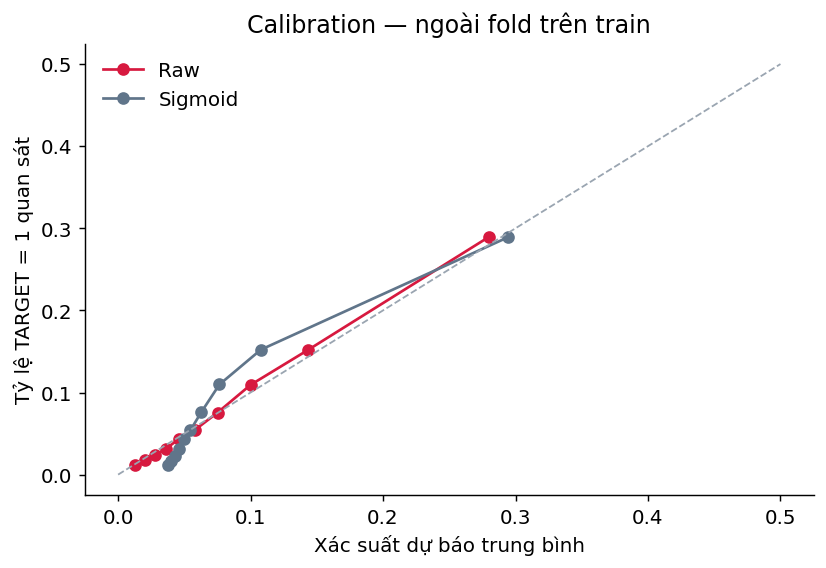

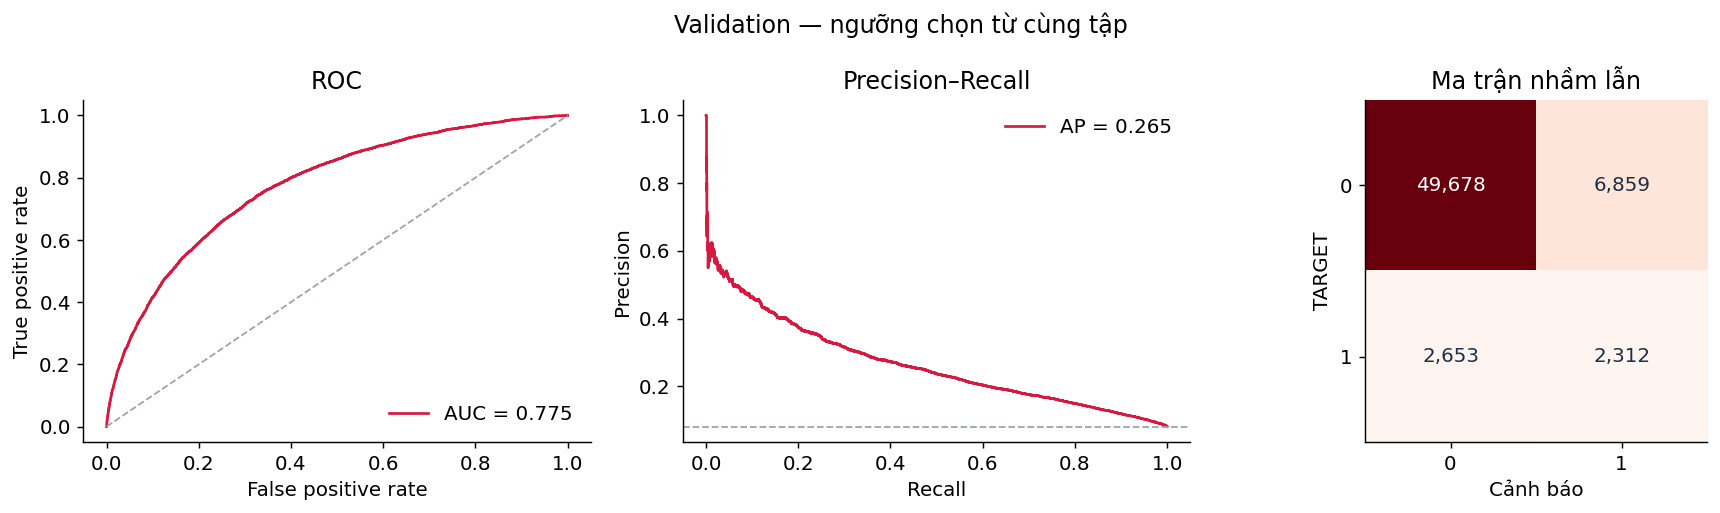

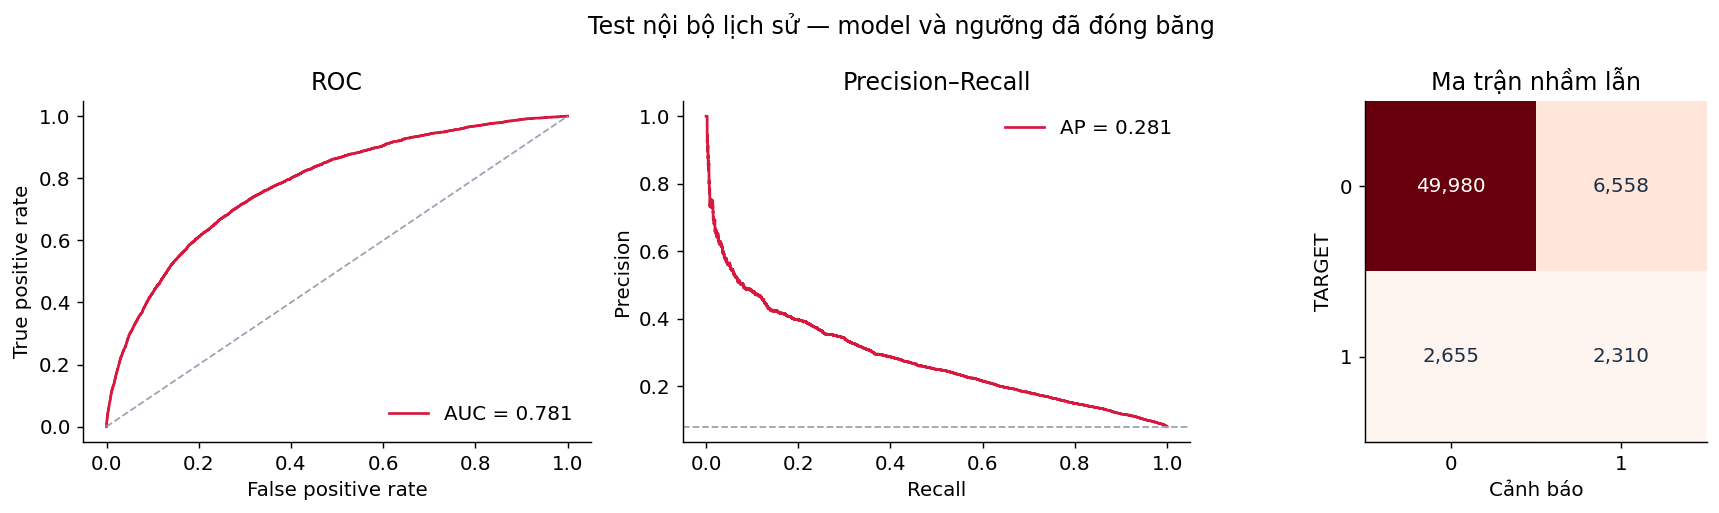

In [7]:
FIGURES = REPORTS / 'figures'
FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': False, 'figure.facecolor': 'white'})
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for method, column, color in [('Raw', 'raw_score', '#D7193F'), ('Sigmoid', 'sigmoid_score', '#60758A')]:
    observed, predicted = calibration_curve(calibration_scores['TARGET'], calibration_scores[column],
                                           n_bins=10, strategy='quantile')
    ax.plot(predicted, observed, marker='o', color=color, label=method)
ax.plot([0, .5], [0, .5], '--', color='#9AA5B1', linewidth=1)
ax.set(xlabel='Xác suất dự báo trung bình', ylabel='Tỷ lệ TARGET = 1 quan sát', title='Calibration — ngoài fold trên train')
ax.legend(frameon=False)
fig.tight_layout()
for ext in ['png', 'pdf']:
    fig.savefig(FIGURES / ('calibration.' + ext), dpi=220, bbox_inches='tight')
plt.show()

def plot_evaluation(rows, title, filename):
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    y, score = rows['TARGET'], rows['score']
    fpr, tpr, _ = roc_curve(y, score)
    axes[0].plot(fpr, tpr, color='#D7193F', label=f'AUC = {roc_auc_score(y, score):.3f}')
    axes[0].plot([0, 1], [0, 1], '--', color='#9AA5B1', linewidth=1)
    axes[0].set(xlabel='False positive rate', ylabel='True positive rate', title='ROC')
    axes[0].legend(frameon=False, loc='lower right')
    precision, recall, _ = precision_recall_curve(y, score)
    axes[1].plot(recall, precision, color='#D7193F', label=f'AP = {average_precision_score(y, score):.3f}')
    axes[1].axhline(y.mean(), linestyle='--', color='#9AA5B1', linewidth=1)
    axes[1].set(xlabel='Recall', ylabel='Precision', title='Precision–Recall')
    axes[1].legend(frameon=False)
    matrix = confusion_matrix(y, score >= threshold, labels=[0, 1])
    axes[2].imshow(matrix, cmap='Reds')
    for i in [0, 1]:
        for j in [0, 1]:
            axes[2].text(j, i, f'{matrix[i, j]:,}', ha='center', va='center',
                         color='white' if matrix[i, j] > matrix.max() / 2 else '#1D3045')
    axes[2].set(xticks=[0, 1], yticks=[0, 1], xlabel='Cảnh báo', ylabel='TARGET', title='Ma trận nhầm lẫn')
    fig.suptitle(title)
    fig.tight_layout()
    for ext in ['png', 'pdf']:
        fig.savefig(FIGURES / (filename + '.' + ext), dpi=220, bbox_inches='tight')
    plt.show()

plot_evaluation(validation, 'Validation — ngưỡng chọn từ cùng tập', 'validation')
plot_evaluation(historical_test, 'Test nội bộ lịch sử — model và ngưỡng đã đóng băng', 'historical_test')

**Kết luận:** biểu đồ và ma trận dùng đúng dự báo của bản 182 biến. AP/AUC không phụ thuộc một ngưỡng cụ thể; ma trận nhầm lẫn và khối lượng cảnh báo thay đổi khi thay ngưỡng.

<a id="part-7"></a>

## 07. Khối lượng rà soát và kết luận

Các mức top 5%, 10% và 20% cho biết đội rà soát cần xử lý bao nhiêu hồ sơ, tìm được bao nhiêu ca TARGET = 1 và có lift bao nhiêu so với chọn ngẫu nhiên. Các mức này dùng để thảo luận năng lực vận hành; chưa phải chính sách phê duyệt hay từ chối tự động.

In [8]:
capacity = pd.DataFrame([
    HomeCreditTraining.capacityMetrics(rows['SK_ID_CURR'], rows['TARGET'], rows['score'], dataset, fraction)
    for dataset, rows in [('validation', validation), ('historical_internal_test', historical_test)]
    for fraction in [.05, .10, .20]
])
capacity.to_csv(REPORTS / 'capacity_metrics.csv', index=False)
display(capacity)
(REPORTS / 'execution.json').write_text(json.dumps({
    'status': 'complete', 'cache_key': cache_key, 'case_id': case_id,
    'final_features': len(final_schema['feature_order']),
    'use_sigmoid': use_sigmoid, 'main_threshold': threshold,
    'model_path': model_path.relative_to(ROOT).as_posix(),
    'metadata_path': (ARTIFACTS / 'inference_metadata.json').relative_to(ROOT).as_posix(),
    'train_n': len(train), 'validation_n': len(validation), 'historical_test_n': len(historical_test),
    'test_used_for_selection': False, 'test_is_new_independent_evaluation': False,
    'dashboard_model_replaced': False,
}, indent=2), encoding='utf-8')

,dataset,fraction,review_n,captured_positive_n,precision,recall,lift,tie_break
0,validation,0.05,3076,1107,0.359883,0.222961,4.457910,"score descending, SK_ID_CURR ascending"
1,validation,0.10,6151,1763,0.286620,0.355086,3.550394,"score descending, SK_ID_CURR ascending"
2,validation,0.20,12301,2721,0.221202,0.548036,2.740048,"score descending, SK_ID_CURR ascending"
3,historical_internal_test,0.05,3076,1160,0.377113,0.233635,4.671418,"score descending, SK_ID_CURR ascending"
4,historical_internal_test,0.10,6151,1820,0.295887,0.366566,3.665242,"score descending, SK_ID_CURR ascending"
5,historical_internal_test,0.20,12301,2805,0.228030,0.564955,2.824682,"score descending, SK_ID_CURR ascending"


**Kết luận:** chọn **raw** theo Brier ngoài fold trên train: raw = 0.06662082, sigmoid = 0.06770763. Model cuối là CatBoost depth=6, 500 vòng, fit trên 184.506 hồ sơ train với **182 biến**.

Ngưỡng cảnh báo chọn trên validation là **14,5394%** theo 5FN + FP. Kết quả tại ngưỡng đã đóng băng:

| Phạm vi | AP | ROC-AUC | Precision | Recall | Tỷ lệ cảnh báo |
| --- | ---: | ---: | ---: | ---: | ---: |
| Validation | 0.264876 | 0.775364 | 25,21% | 46,57% | 14,91% |
| Test nội bộ lịch sử | 0.280743 | 0.781073 | 26,05% | 46,53% | 14,42% |

Tại ngưỡng này, 74,79% số cảnh báo validation là ca TARGET = 0 và 53,43% ca TARGET = 1 bị bỏ sót. Model hỗ trợ xếp thứ tự rà soát; các chỉ số hiện tại chưa đủ để tự chốt chính sách duyệt hoặc từ chối tự động khi chưa có giới hạn chi phí, năng lực xử lý và mục tiêu rủi ro của đơn vị sử dụng.

Model, ngưỡng và các dự báo mới đã lưu trong `reports/modeling/selected_model_evaluation_20261030/` cùng thư mục artifact ghi trong `execution.json`. Đã kiểm tra nạp model bằng `CreditRiskModel` và đối chiếu điểm chấm với dự báo trực tiếp. Dashboard vẫn dùng model đã triển khai trước đó.

Notebook 08 đã cập nhật theo artifact 182 biến để giải thích đặc trưng, minh họa sai số và phân tầng rủi ro. Phiên bản hiện tại đã được chốt cho đồ án; việc tích hợp lên dashboard là bước tiếp theo. Test trong bảng là test lịch sử đã được xem; model và ngưỡng được đóng băng trước lần chấm này và không được chọn lại từ các chỉ số test.
